# Glasses in the Wild

> Real-world photos of transparent drinking glasses in diverse scenes (lighting, backgrounds, viewpoints).

**GT available (per image):**
- Keypoints for glass geometry + fluid level (from `images/annotations.json`)
- Visibility flag per keypoint (`v`)
- Derived fill percentage from keypoints (`fill_percentage`, when computable)

In [ ]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Make repo dataset loaders importable in notebooks.
sys.path.append(str(Path("..") / "src"))
from datasets.glassesinthewild import GlassesInTheWildDataset

ROOT = Path("..") / "data" / "glasses_in_the_wild"
assert ROOT.exists(), f"Dataset root not found: {ROOT}"

SPLITS = {
    "full": ROOT / "glasses_in_the_wild_1000",
    "train": ROOT / "glasses_in_the_wild_1000_train",
    "val": ROOT / "glasses_in_the_wild_1000_val",
}

DATASETS: dict[str, GlassesInTheWildDataset] = {}
for split, path in SPLITS.items():
    ok = path.exists() and (path / "images" / "annotations.json").exists()
    print(f"{split:<5} -> {path} (ok={ok})")
    if ok:
        DATASETS[split] = GlassesInTheWildDataset(path)

full  -> ../data/glasses_in_the_wild/glasses_in_the_wild_1000 (exists=True)
train -> ../data/glasses_in_the_wild/glasses_in_the_wild_1000_train (exists=True)
val   -> ../data/glasses_in_the_wild/glasses_in_the_wild_1000_val (exists=True)


## Capability audit across dataset variants

The dataset ships multiple folder variants and annotation artifacts:

- **Full set** (`glasses_in_the_wild_1000`) with `annotations.xml`, plus explicit `annotations_train.xml` and `annotations_val.xml`.
- **Split folders** (`..._train`, `..._val`) each with `annotations.xml` and `images/annotations.json`.
- **Image modality** is RGB crops (`256x256` PNGs).
- **Annotation capability** focuses on 5 keypoints per glass: geometry + fluid level.

## Annotation schema deep-dive

This dataset provides two complementary annotation representations:

- **CVAT XML** (`annotations.xml`) with per-image `<points>` elements.
- **COCO-style JSON** (`images/annotations.json`) with `images`, `annotations`, `categories`, and flattened keypoints.

In [ ]:
def get_dataset(split: str) -> GlassesInTheWildDataset:
    if split not in DATASETS:
        raise ValueError(f"Split {split!r} is unavailable. Available: {sorted(DATASETS)}")
    return DATASETS[split]

## Dataset statistics and keypoint distributions

The next cell computes:

- image/annotation counts for each split,
- keypoint visibility statistics from COCO keypoints (the `v` channel),
- coordinate distributions for each semantic keypoint,
- and a derived fill-level ratio using `fluid_level` and `bottom_front` vertical coordinates.

In [ ]:
from collections import Counter

# Back-compat with older notebook structure: this now returns a dataset instance.
def load_dataset_for_split(split: str) -> GlassesInTheWildDataset:
    return get_dataset(split)


def summarize_split(split: str):
    ds = load_dataset_for_split(split)
    visible = Counter()
    total = Counter()
    fill_values = []

    for sample in ds:
        kps = sample.get("keypoints")
        if isinstance(kps, dict):
            for name, pt in kps.items():
                if not isinstance(pt, dict):
                    continue
                total[name] += 1
                v = pt.get("v")
                if isinstance(v, (int, float)) and v > 0:
                    visible[name] += 1

        fill = sample.get("fill_percentage")
        if isinstance(fill, (int, float)):
            fill_values.append(float(fill))

    print(f"{split}: n={len(ds)} | fill% available={len(fill_values)}")
    if total:
        print("Keypoint visibility (visible/total):")
        for name in sorted(total):
            print(f"- {name:14s} {visible[name]:>4d}/{total[name]:<4d}")
    return fill_values


fills_by_split = {s: summarize_split(s) for s in sorted(DATASETS)}

plt.figure(figsize=(9, 3.5))
for split, vals in fills_by_split.items():
    if vals:
        plt.hist(vals, bins=20, alpha=0.6, label=split)
plt.title("Derived fill percentage distribution")
plt.xlabel("fill_percentage")
plt.ylabel("count")
plt.legend()
plt.tight_layout()
plt.show()

## Qualitative visualization: keypoints overlaid on images

The following utility overlays all 5 keypoints on selected images and connects key geometry lines:

- top-left ↔ top-right,
- top-front ↔ bottom-front,
- and fluid-level marker.

This helps verify annotation quality and gives an intuitive sense of task difficulty.

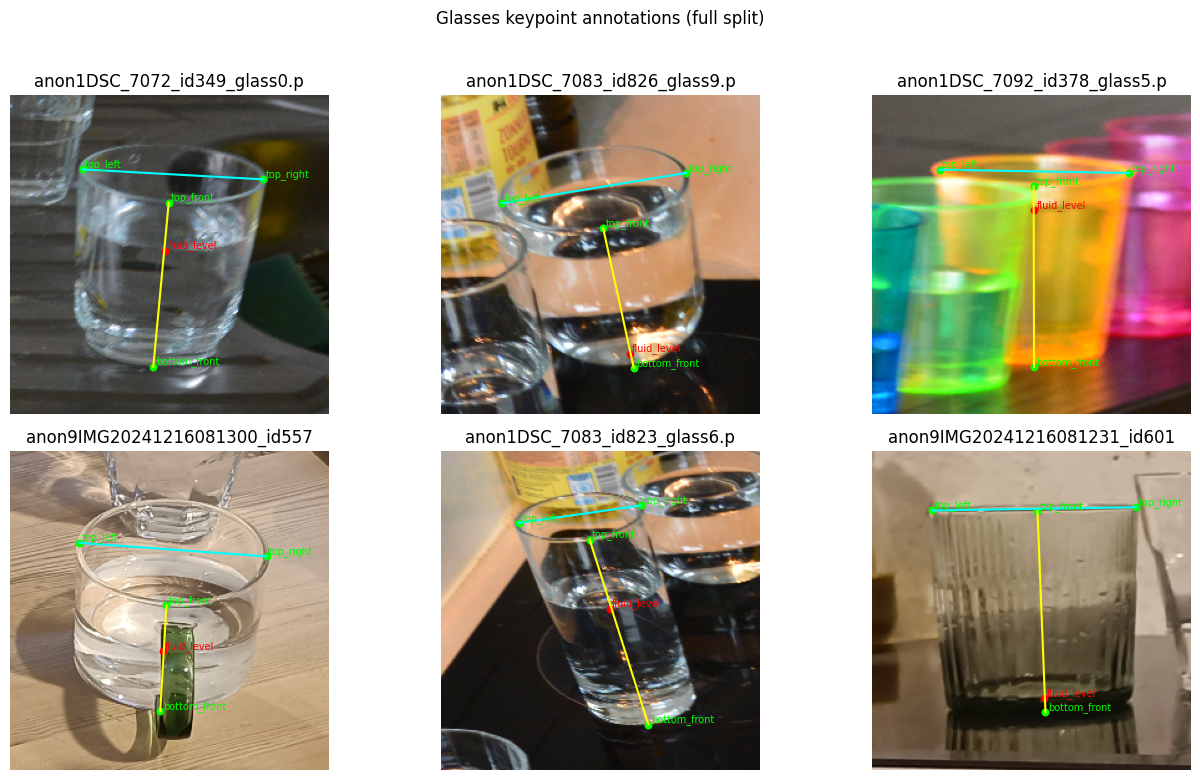

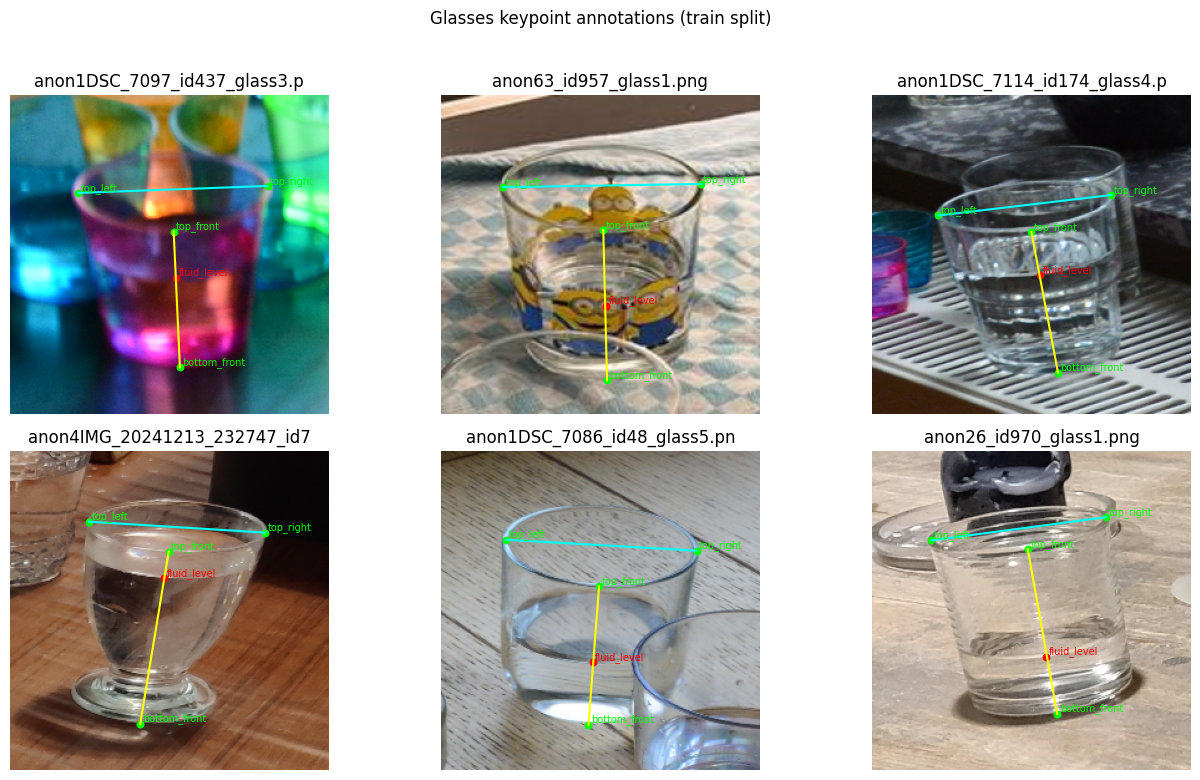

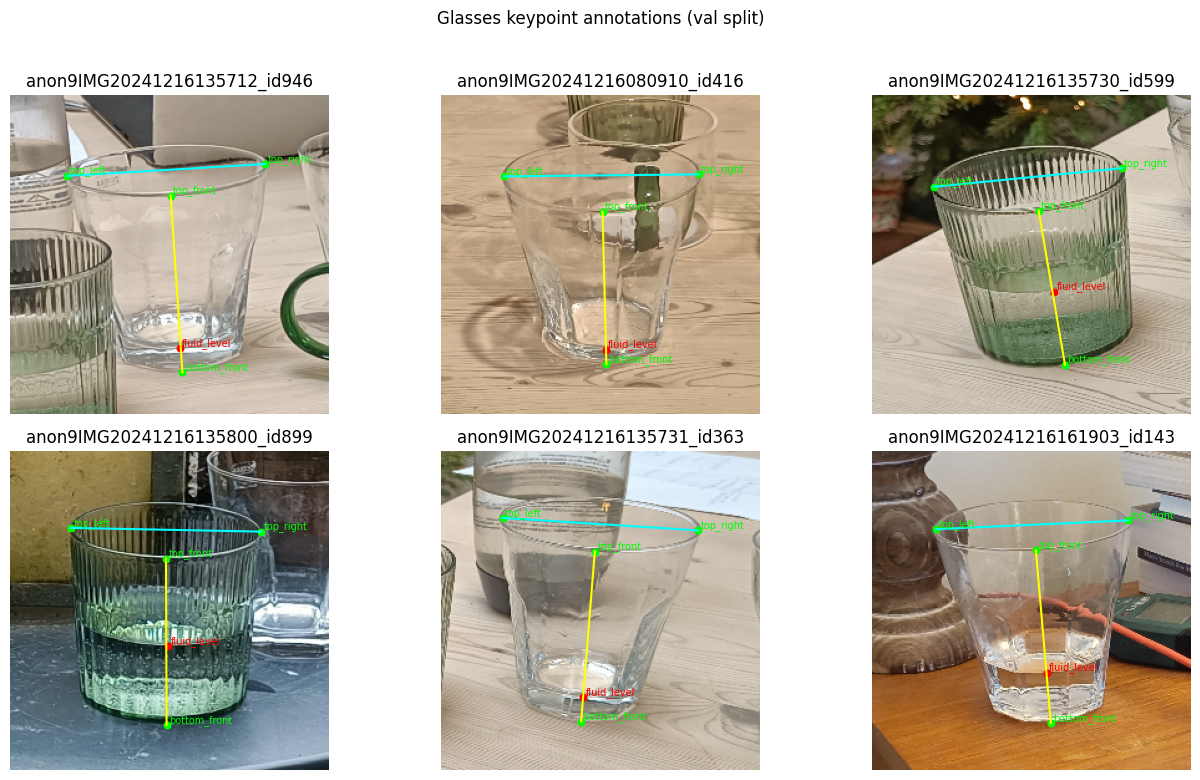

In [ ]:
def read_img(path: Path):
    if not path.exists():
        return None
    return plt.imread(path)


def show_samples(split: str = "full", n: int = 6, seed: int = 7):
    ds = load_dataset_for_split(split)
    if len(ds) == 0:
        print(f"No samples for split={split!r}")
        return

    rng = np.random.default_rng(seed)
    idxs = rng.choice(len(ds), size=min(n, len(ds)), replace=False)
    chosen = [ds[int(i)] for i in idxs]

    cols = 3
    rows = int(np.ceil(len(chosen) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4.5 * cols, 3.8 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, sample in zip(axes, chosen):
        img_path = sample.get("rgb_image")
        if not isinstance(img_path, Path):
            ax.set_title("Missing image path")
            ax.axis("off")
            continue

        img = read_img(img_path)
        if img is None:
            ax.set_title(f"Missing: {img_path.name}")
            ax.axis("off")
            continue

        kps = sample.get("keypoints")
        ax.imshow(img)
        if isinstance(kps, dict) and kps:
            # draw points
            for name, pt in kps.items():
                if not isinstance(pt, dict):
                    continue
                x, y, v = pt.get("x"), pt.get("y"), pt.get("v")
                if isinstance(v, (int, float)) and v > 0 and isinstance(x, (int, float)) and isinstance(y, (int, float)):
                    color = "red" if name == "fluid_level" else "lime"
                    ax.scatter(x, y, s=22, c=color)
                    ax.text(x + 2, y - 2, name, color=color, fontsize=7)

            # geometry helper lines (if present)
            def _pt(n: str):
                p = kps.get(n)
                if not isinstance(p, dict):
                    return None
                if p.get("v", 0) <= 0:
                    return None
                return float(p["x"]), float(p["y"])

            tl = _pt("top_left")
            tr = _pt("top_right")
            tf = _pt("top_front")
            bf = _pt("bottom_front")
            if tl and tr:
                ax.plot([tl[0], tr[0]], [tl[1], tr[1]], c="cyan", lw=1.5)
            if tf and bf:
                ax.plot([tf[0], bf[0]], [tf[1], bf[1]], c="yellow", lw=1.5)

        name = str(sample.get("image_name", img_path.name))
        fill = sample.get("fill_percentage")
        fill_str = f" | fill={float(fill):.1f}%" if isinstance(fill, (int, float)) else ""
        ax.set_title(f"{name[:28]}{fill_str}")
        ax.axis("off")

    for ax in axes[len(chosen) :]:
        ax.axis("off")

    fig.suptitle(f"Glasses keypoint annotations ({split} split)", y=1.02)
    plt.tight_layout()
    plt.show()


show_samples("full", n=6, seed=3)
show_samples("train", n=6, seed=9)
show_samples("val", n=6, seed=13)